In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path("../../data")

df_main      = pd.read_csv(DATA_DIR / "DataSheet_Main.csv", skiprows=4)
df_gdp       = pd.read_csv(DATA_DIR / "DataSheet_GDP.csv",  skiprows=4)
country_meta = pd.read_csv(DATA_DIR / "Metadata_Country.csv").dropna(axis=1, how="all")

selected_codes = [
    "FS.AST.PRVT.GD.ZS",    # domestic credit
    "FB.CBK.BRCH.P5",        # bank branches
    "FB.ATM.TOTL.P5",        # ATMs
    "CM.MKT.LCAP.GD.ZS",    # market cap
    "FR.INR.LNDP",           # interest spread
    "FM.LBL.BMNY.GD.ZS",    # broad money
    "BX.KLT.DINV.WD.GD.ZS", # FDI inflows
    "FB.AST.NPER.ZS",        # nonperforming loans
    "NY.GDP.DEFL.KD.ZG.AD",  # inflation
]

years    = [str(y) for y in range(2004, 2022)]
id_cols  = ["Country Name", "Indicator Name"]

region_codes = country_meta[
    country_meta["Region"].isna() & country_meta["IncomeGroup"].isna()
]["Country Code"].tolist()

df_f     = df_main[df_main["Indicator Code"].isin(selected_codes)]
df_f     = df_f[~df_f["Country Code"].isin(region_codes)][id_cols + years]
df_gdp_f = df_gdp[df_gdp["Indicator Code"] == "NY.GDP.MKTP.KD.ZG"]
df_gdp_f = df_gdp_f[~df_gdp_f["Country Code"].isin(region_codes)][id_cols + years]

combined = pd.concat([df_f, df_gdp_f], ignore_index=True)
df_long  = combined.melt(id_vars=id_cols, value_vars=years, var_name="Year", value_name="Value")
df_long["Year"]  = df_long["Year"].astype(int)
df_long["Value"] = pd.to_numeric(df_long["Value"], errors="coerce")

df_panel = df_long.pivot_table(
    index=["Country Name", "Year"],
    columns="Indicator Name",
    values="Value"
).reset_index()

df_panel = df_panel.rename(columns={
    "GDP growth (annual %)": "gdp_growth",
    "Domestic credit to private sector (% of GDP)": "domestic_credit",
    "Commercial bank branches (per 100,000 adults)": "bank_branches",
    "Automated teller machines (ATMs) (per 100,000 adults)": "atms",
    "Market capitalization of listed domestic companies (% of GDP)": "market_cap",
    "Interest rate spread (lending rate minus deposit rate, %)": "interest_spread",
    "Broad money (% of GDP)": "broad_money",
    "Foreign direct investment, net inflows (% of GDP)": "fdi_inflows",
    "Bank nonperforming loans to total gross loans (%)": "nonperforming_loans",
    "Inflation, GDP deflator: linked series (annual %)": "inflation",
})

df_panel = df_panel.merge(
    country_meta[["TableName", "IncomeGroup", "Region"]],
    left_on="Country Name", right_on="TableName", how="left"
).drop(columns="TableName")

INCOME_ORDER = ["Low income", "Lower middle income", "Upper middle income", "High income"]
df_panel["IncomeGroup"] = pd.Categorical(df_panel["IncomeGroup"], categories=INCOME_ORDER, ordered=True)

COLORS = {
    "Low income":           "#2ecc71",
    "Lower middle income":  "#f39c12",
    "Upper middle income":  "#3498db",
    "High income":          "#e74c3c",
}
CHANNELS = ["domestic_credit", "broad_money", "bank_branches", "atms", "fdi_inflows"]

print(df_panel.shape)
df_panel.head(3)

(3831, 14)


,Country Name,Year,atms,nonperforming_loans,broad_money,bank_branches,domestic_credit,fdi_inflows,gdp_growth,inflation,interest_spread,market_cap,IncomeGroup,Region
0,Afghanistan,2004,0.02,NaN,NaN,0.37,NaN,3.577104,1.414118,11.271432,NaN,NaN,Low income,South Asia
1,Afghanistan,2005,0.06,NaN,NaN,0.58,NaN,4.368673,11.229715,10.912774,NaN,NaN,Low income,South Asia
2,Afghanistan,2006,0.12,NaN,23.343865,0.92,4.842857,3.413773,5.357403,7.199751,NaN,NaN,Low income,South Asia


## SQ3 — 2008 Global Financial Crisis

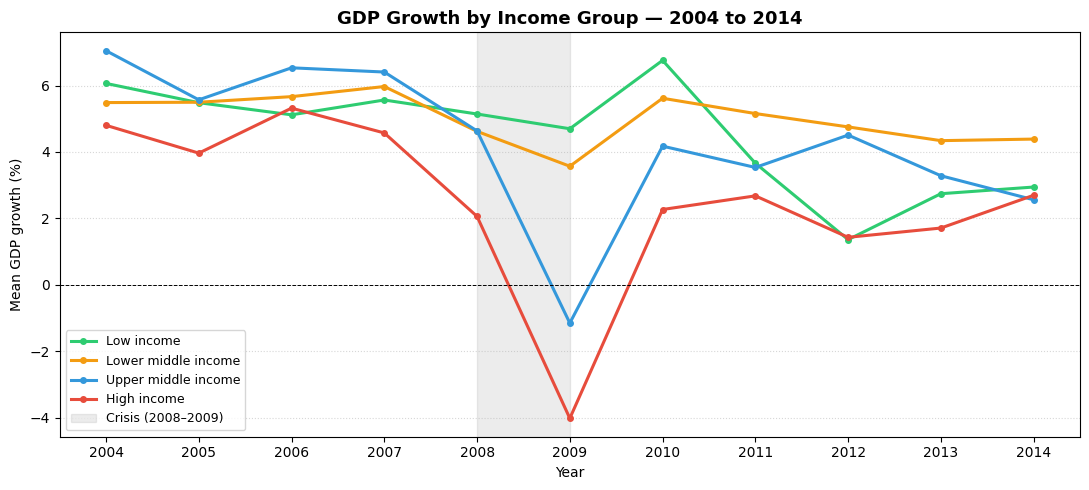

In [2]:
# GDP growth trajectory 2004–2014 by income group
df_08 = df_panel[df_panel["Year"].between(2004, 2014)].copy()

line_data = (
    df_08.groupby(["IncomeGroup", "Year"])["gdp_growth"]
    .mean()
    .reset_index()
)

fig, ax = plt.subplots(figsize=(11, 5))
for group in INCOME_ORDER:
    d = line_data[line_data["IncomeGroup"] == group]
    ax.plot(d["Year"], d["gdp_growth"], color=COLORS[group], linewidth=2.2,
            label=group, marker="o", markersize=4)

ax.axvspan(2008, 2009, color="grey", alpha=0.15, label="Crisis (2008–2009)")
ax.axhline(0, color="black", linewidth=0.7, linestyle="--")
ax.set_title("GDP Growth by Income Group — 2004 to 2014", fontsize=13, fontweight="bold")
ax.set_xlabel("Year")
ax.set_ylabel("Mean GDP growth (%)")
ax.set_xticks(range(2004, 2015))
ax.legend(loc="lower left", fontsize=9)
ax.grid(axis="y", linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()

In [3]:
# Deviation score per country:
# drop = gdp_growth_2009 - average_gdp_growth(2004-2007)
# Negative = fell below its own pre-crisis trend
# More negative = hit harder relative to that country's own baseline

df_08["period"] = pd.cut(
    df_08["Year"],
    bins=[2003, 2007, 2009, 2014],
    labels=["pre_crisis", "crisis", "recovery"]
)

pre_avg = (
    df_08[df_08["period"] == "pre_crisis"]
    .groupby("Country Name")["gdp_growth"]
    .mean()
    .rename("pre_crisis_avg")
)

crisis_09 = (
    df_08[df_08["Year"] == 2009]
    .set_index("Country Name")["gdp_growth"]
    .rename("gdp_2009")
)

deviation = pd.concat([pre_avg, crisis_09], axis=1).dropna()
deviation["drop"] = deviation["gdp_2009"] - deviation["pre_crisis_avg"]

print(f"Countries scored: {len(deviation)}")
print(deviation["drop"].describe().round(2))
print("\nHardest hit (largest negative drop from own baseline):")
deviation.sort_values("drop").head(10)

Countries scored: 205
count    205.00
mean      -5.69
std        6.32
min      -26.94
25%       -8.71
50%       -4.87
75%       -1.80
max       17.93
Name: drop, dtype: float64

Hardest hit (largest negative drop from own baseline):


,pre_crisis_avg,gdp_2009,drop
Country Name,,,
Latvia,10.895004,-16.040020,-26.935024
Armenia,12.825000,-14.100000,-26.925000
Estonia,8.414311,-14.630223,-23.044534
Lithuania,8.176723,-14.838612,-23.015335
Ukraine,7.663462,-15.136468,-22.799930
Antigua and Barbuda,8.566031,-11.962879,-20.528910
Botswana,5.354724,-14.144235,-19.498958
Equatorial Guinea,19.433615,1.343356,-18.090258
Monaco,6.155265,-11.336987,-17.492251


Pre-crisis financial profile (medians):
                 Resilient (top 10%)  Hardest hit (bottom 10%)
domestic_credit                 10.2                      39.8
broad_money                     23.6                      41.3
bank_branches                    2.6                      14.1
atms                             1.8                      29.1
fdi_inflows                      2.1                       5.8


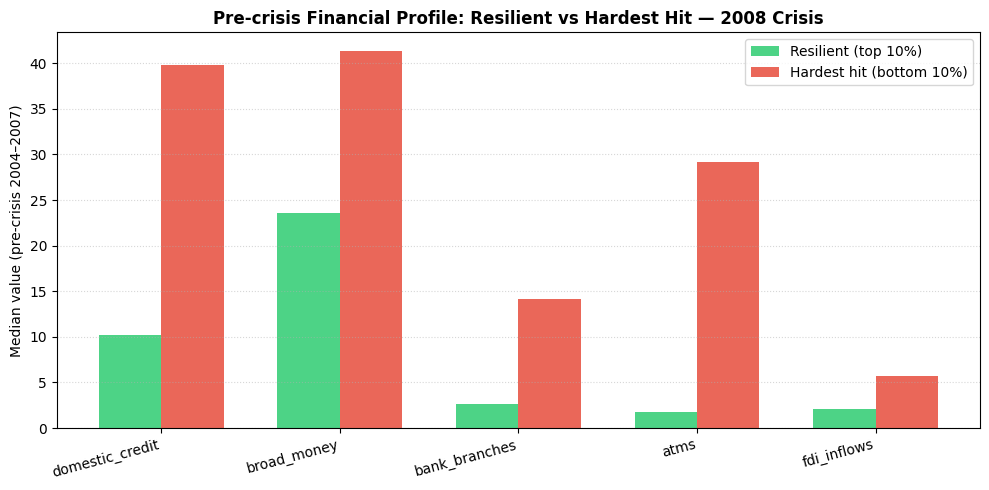

In [4]:
# Pre-crisis financial profile: top 10% resilient vs bottom 10% hardest hit
n = max(1, int(len(deviation) * 0.1))
resilient = deviation.nlargest(n, "drop").index   # smallest drop
hardest   = deviation.nsmallest(n, "drop").index  # largest drop

pre_profiles = (
    df_08[df_08["period"] == "pre_crisis"]
    .groupby("Country Name")[CHANNELS]
    .mean()
)

p_res = pre_profiles.loc[pre_profiles.index.isin(resilient)].median()
p_hit = pre_profiles.loc[pre_profiles.index.isin(hardest)].median()

print("Pre-crisis financial profile (medians):")
print(pd.DataFrame({"Resilient (top 10%)": p_res, "Hardest hit (bottom 10%)": p_hit}).round(1))

x = range(len(CHANNELS))
w = 0.35
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar([i - w/2 for i in x], p_res, w, label="Resilient (top 10%)",      color="#2ecc71", alpha=0.85)
ax.bar([i + w/2 for i in x], p_hit, w, label="Hardest hit (bottom 10%)", color="#e74c3c", alpha=0.85)
ax.set_xticks(list(x))
ax.set_xticklabels(CHANNELS, rotation=15, ha="right")
ax.set_ylabel("Median value (pre-crisis 2004–2007)")
ax.set_title("Pre-crisis Financial Profile: Resilient vs Hardest Hit — 2008 Crisis", fontweight="bold")
ax.legend()
ax.grid(axis="y", linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()

## SQ4 — COVID-19 Shock 2020

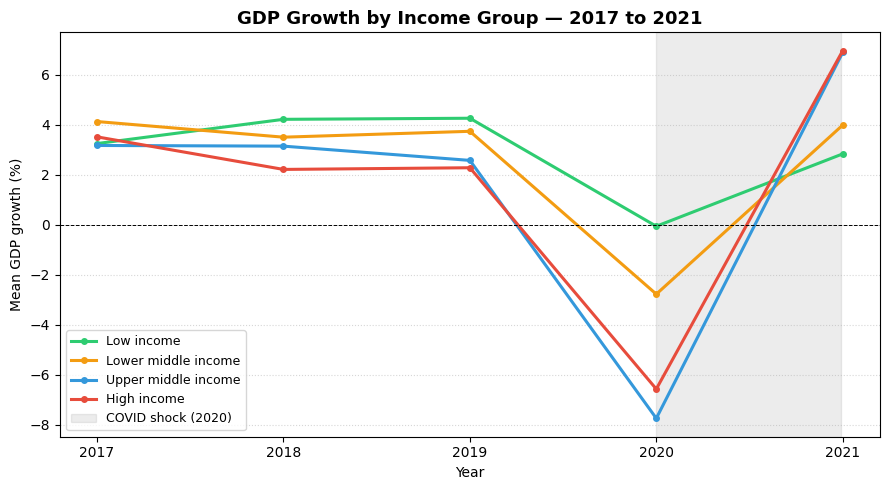

In [5]:
# GDP growth trajectory 2017–2021 by income group
df_cov = df_panel[df_panel["Year"].between(2017, 2021)].copy()

line_data_cov = (
    df_cov.groupby(["IncomeGroup", "Year"])["gdp_growth"]
    .mean()
    .reset_index()
)

fig, ax = plt.subplots(figsize=(9, 5))
for group in INCOME_ORDER:
    d = line_data_cov[line_data_cov["IncomeGroup"] == group]
    ax.plot(d["Year"], d["gdp_growth"], color=COLORS[group], linewidth=2.2,
            label=group, marker="o", markersize=4)

ax.axvspan(2020, 2020.99, color="grey", alpha=0.15, label="COVID shock (2020)")
ax.axhline(0, color="black", linewidth=0.7, linestyle="--")
ax.set_title("GDP Growth by Income Group — 2017 to 2021", fontsize=13, fontweight="bold")
ax.set_xlabel("Year")
ax.set_ylabel("Mean GDP growth (%)")
ax.set_xticks(range(2017, 2022))
ax.legend(loc="lower left", fontsize=9)
ax.grid(axis="y", linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()

In [6]:
# Same deviation logic: drop = gdp_2020 - avg(2017-2019)
df_cov["period"] = pd.cut(
    df_cov["Year"],
    bins=[2016, 2019, 2020, 2021],
    labels=["pre_covid", "shock", "recovery"]
)

pre_avg_cov = (
    df_cov[df_cov["period"] == "pre_covid"]
    .groupby("Country Name")["gdp_growth"]
    .mean()
    .rename("pre_covid_avg")
)

shock_20 = (
    df_cov[df_cov["Year"] == 2020]
    .set_index("Country Name")["gdp_growth"]
    .rename("gdp_2020")
)

deviation_cov = pd.concat([pre_avg_cov, shock_20], axis=1).dropna()
deviation_cov["drop"] = deviation_cov["gdp_2020"] - deviation_cov["pre_covid_avg"]

print(f"Countries scored: {len(deviation_cov)}")
print(deviation_cov["drop"].describe().round(2))
print("\nHardest hit (largest negative drop from own baseline):")
deviation_cov.sort_values("drop").head(10)

Countries scored: 210
count    210.00
mean      -8.34
std        9.05
min      -62.59
25%      -11.08
50%       -6.75
75%       -4.02
max       38.97
Name: drop, dtype: float64

Hardest hit (largest negative drop from own baseline):


,pre_covid_avg,gdp_2020,drop
Country Name,,,
Turks and Caicos Islands,28.774114,-33.817097,-62.591211
"Macao SAR, China",4.605606,-54.402093,-59.007699
Maldives,7.522148,-32.908829,-40.430977
Libya,9.745696,-29.455297,-39.200992
Aruba,2.643671,-23.897990,-26.541661
Northern Mariana Islands,-2.591365,-29.059829,-26.468464
St. Lucia,1.855428,-24.361473,-26.216901
Cabo Verde,5.068702,-20.805276,-25.873978
Antigua and Barbuda,4.198984,-18.868777,-23.067761


Pre-COVID financial profile (medians):
                 Resilient (top 10%)  Hardest hit (bottom 10%)
domestic_credit                 25.2                      53.6
broad_money                     43.7                      81.7
bank_branches                    8.2                      22.1
atms                            20.6                      56.9
fdi_inflows                      3.3                       5.4


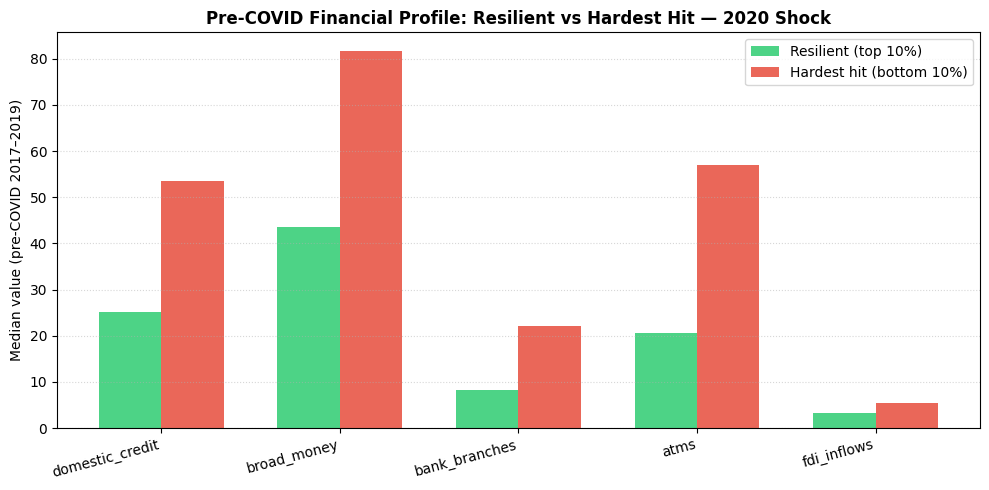

In [7]:
# Pre-COVID financial profile: top 10% resilient vs bottom 10% hardest hit
n_cov     = max(1, int(len(deviation_cov) * 0.1))
res_cov   = deviation_cov.nlargest(n_cov, "drop").index
hit_cov   = deviation_cov.nsmallest(n_cov, "drop").index

pre_profiles_cov = (
    df_cov[df_cov["period"] == "pre_covid"]
    .groupby("Country Name")[CHANNELS]
    .mean()
)

p_res_cov = pre_profiles_cov.loc[pre_profiles_cov.index.isin(res_cov)].median()
p_hit_cov = pre_profiles_cov.loc[pre_profiles_cov.index.isin(hit_cov)].median()

print("Pre-COVID financial profile (medians):")
print(pd.DataFrame({"Resilient (top 10%)": p_res_cov, "Hardest hit (bottom 10%)": p_hit_cov}).round(1))

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar([i - w/2 for i in x], p_res_cov, w, label="Resilient (top 10%)",      color="#2ecc71", alpha=0.85)
ax.bar([i + w/2 for i in x], p_hit_cov, w, label="Hardest hit (bottom 10%)", color="#e74c3c", alpha=0.85)
ax.set_xticks(list(x))
ax.set_xticklabels(CHANNELS, rotation=15, ha="right")
ax.set_ylabel("Median value (pre-COVID 2017–2019)")
ax.set_title("Pre-COVID Financial Profile: Resilient vs Hardest Hit — 2020 Shock", fontweight="bold")
ax.legend()
ax.grid(axis="y", linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()

"## Comparison — Were the Same Countries Hit Hard in Both Crises?"

Average deviation score by group and crisis:
                    2008 hardest hit  2020 hardest hit
Their drop in 2008             -18.1              -8.9
Their drop in 2020             -13.5             -24.5


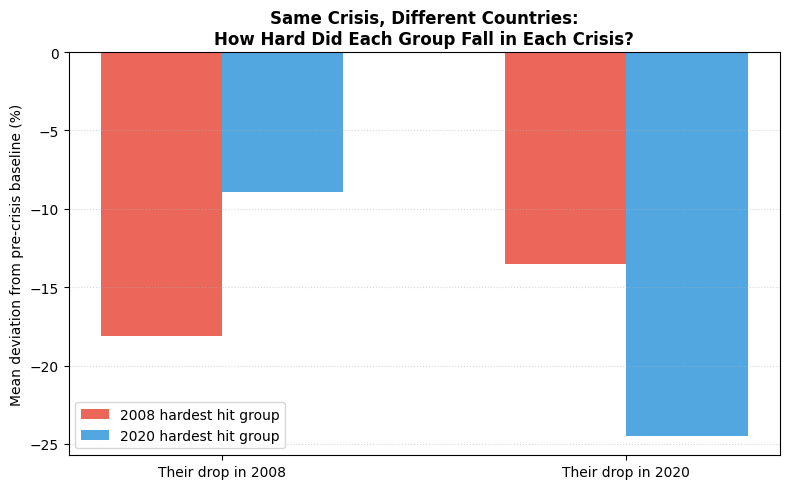


2008 hardest hit countries: ['Latvia', 'Armenia', 'Estonia', 'Lithuania', 'Ukraine', 'Antigua and Barbuda', 'Botswana', 'Equatorial Guinea', 'Monaco', 'Kuwait', 'Iceland', 'Russian Federation', 'Chad', 'Venezuela, RB', 'Azerbaijan', 'San Marino', 'Maldives', 'Argentina', 'Aruba', 'Macao SAR, China']

2020 hardest hit countries: ['Macao SAR, China', 'Maldives', 'Libya', 'Aruba', 'Northern Mariana Islands', 'St. Lucia', 'Cabo Verde', 'Antigua and Barbuda', 'Panama', 'Bahamas, The', 'Fiji', 'Montenegro', 'Lebanon', 'Suriname', 'Mauritius', 'Seychelles', 'St. Kitts and Nevis', 'Grenada', 'Monaco', 'Curacao']


In [8]:
# Merge both deviation scores on country name
both = deviation[["drop"]].rename(columns={"drop": "drop_2008"}).join(
    deviation_cov[["drop"]].rename(columns={"drop": "drop_2020"}),
    how="inner"
)

# Define hardest-hit groups from each crisis (bottom 10%)
n_comp = max(1, int(len(both) * 0.1))
hit_08_countries  = both.nsmallest(n_comp, "drop_2008").index   # worst in 2008
hit_cov_countries = both.nsmallest(n_comp, "drop_2020").index   # worst in 2020

# For each group: how hard did they fall in BOTH crises?
summary = pd.DataFrame({
    "2008 hardest hit": [
        both.loc[hit_08_countries,  "drop_2008"].mean().round(1),
        both.loc[hit_08_countries,  "drop_2020"].mean().round(1),
    ],
    "2020 hardest hit": [
        both.loc[hit_cov_countries, "drop_2008"].mean().round(1),
        both.loc[hit_cov_countries, "drop_2020"].mean().round(1),
    ],
}, index=["Their drop in 2008", "Their drop in 2020"])

print("Average deviation score by group and crisis:")
print(summary)

# Bar chart
fig, ax = plt.subplots(figsize=(8, 5))
x = [0, 1]
w = 0.3
ax.bar([i - w/2 for i in x], summary["2008 hardest hit"], w,
       label="2008 hardest hit group", color="#e74c3c", alpha=0.85)
ax.bar([i + w/2 for i in x], summary["2020 hardest hit"], w,
       label="2020 hardest hit group", color="#3498db", alpha=0.85)

ax.set_xticks(x)
ax.set_xticklabels(["Their drop in 2008", "Their drop in 2020"])
ax.axhline(0, color="black", linewidth=0.7, linestyle="--")
ax.set_ylabel("Mean deviation from pre-crisis baseline (%)")
ax.set_title("Same Crisis, Different Countries:\nHow Hard Did Each Group Fall in Each Crisis?", fontweight="bold")
ax.legend()
ax.grid(axis="y", linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()

print("\n2008 hardest hit countries:", list(hit_08_countries))
print("\n2020 hardest hit countries:", list(hit_cov_countries))


"## Linear Regression — Train on 2008, Predict 2020"

In [1]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error
import warnings
warnings.filterwarnings("ignore")

# --- build feature matrices ---
# pre-crisis financial profile per country (mean over the window)
def build_features(df_window, period_label, channels):
    return (
        df_window[df_window["period"] == period_label]
        .groupby("Country Name")[channels]
        .mean()
        .dropna()
    )

X_2008 = build_features(df_08,  "pre_crisis", CHANNELS)
X_2020 = build_features(df_cov, "pre_covid",  CHANNELS)

# align with deviation scores
train = X_2008.join(deviation[["drop"]],    how="inner").dropna()
test  = X_2020.join(deviation_cov[["drop"]], how="inner").dropna()

# keep only countries present in both
common = train.index.intersection(test.index)
train  = train.loc[common]
test   = test.loc[common]

X_train = train[CHANNELS].values
y_train = train["drop"].values
X_test  = test[CHANNELS].values
y_test  = test["drop"].values

# --- fit on 2008, predict 2020 ---
model = LinearRegression()
model.fit(X_train, y_train)

y_pred_2008 = model.predict(X_train)   # in-sample (2008)
y_pred_2020 = model.predict(X_test)    # out-of-sample (2020)

r2_2008 = r2_score(y_train, y_pred_2008)
r2_2020 = r2_score(y_test,  y_pred_2020)
mae_2008 = mean_absolute_error(y_train, y_pred_2008)
mae_2020 = mean_absolute_error(y_test,  y_pred_2020)

print("=== Model trained on 2008 ===")
print(f"R²  on 2008 (in-sample):       {r2_2008:.3f}")
print(f"R²  on 2020 (out-of-sample):   {r2_2020:.3f}")
print(f"MAE on 2008:  {mae_2008:.2f} pp")
print(f"MAE on 2020:  {mae_2020:.2f} pp")
print()
print("Coefficients:")
for name, coef in zip(CHANNELS, model.coef_):
    print(f"  {name:20s}  {coef:+.3f}")


NameError: name 'df_08' is not defined

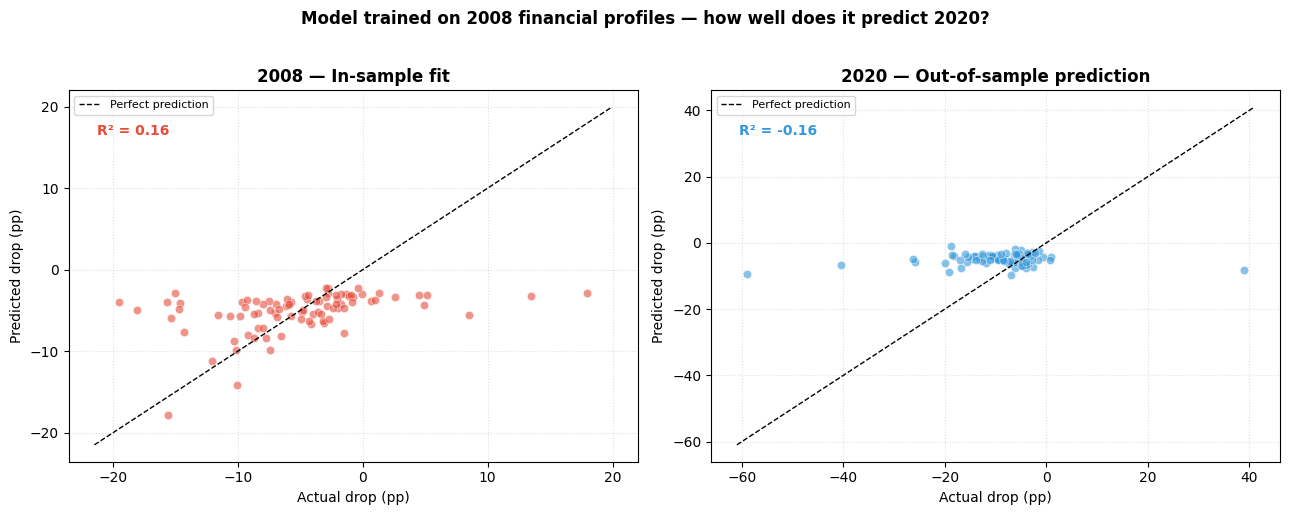

In [10]:
# --- scatter: predicted vs actual for both crises ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=False)

for ax, y_true, y_pred, title, color in zip(
    axes,
    [y_train, y_test],
    [y_pred_2008, y_pred_2020],
    ["2008 — In-sample fit", "2020 — Out-of-sample prediction"],
    ["#e74c3c", "#3498db"]
):
    ax.scatter(y_true, y_pred, color=color, alpha=0.6, edgecolors="white", linewidth=0.5)
    lims = [min(y_true.min(), y_pred.min()) - 2, max(y_true.max(), y_pred.max()) + 2]
    ax.plot(lims, lims, "k--", linewidth=1, label="Perfect prediction")
    ax.set_xlabel("Actual drop (pp)")
    ax.set_ylabel("Predicted drop (pp)")
    ax.set_title(title, fontweight="bold")
    ax.legend(fontsize=8)
    ax.grid(linestyle=":", alpha=0.4)
    r2 = r2_score(y_true, y_pred)
    ax.annotate(f"R² = {r2:.2f}", xy=(0.05, 0.88), xycoords="axes fraction", fontsize=10,
                color=color, fontweight="bold")

plt.suptitle("Model trained on 2008 financial profiles — how well does it predict 2020?",
             fontsize=12, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


## Slide 8 — Who Got Hit and Why: Selected Country Comparison

Horizontal bar chart showing how far each country fell below its own pre-crisis growth trend (deviation score = GDP growth 2009 minus average 2004–2007). Red = financially integrated high-income economies; green = low-income countries with minimal global financial connections.

In [ ]:
from matplotlib.patches import Patch

hit_countries = {
    "Latvia":        "Latvia",
    "Estonia":       "Estonia",
    "Lithuania":     "Lithuania",
    "Germany":       "Germany",
    "United States": "USA",
}
resilient_countries = {
    "Tanzania":  "Tanzania",
    "Ethiopia":  "Ethiopia",
    "Uganda":    "Uganda",
}

def get_scores(name_map):
    rows = []
    for wb_name, label in name_map.items():
        if wb_name in deviation.index:
            rows.append({"label": label, "drop": deviation.loc[wb_name, "drop"]})
        else:
            match = [c for c in deviation.index if wb_name.lower() in c.lower()]
            if match:
                rows.append({"label": label, "drop": deviation.loc[match[0], "drop"]})
            else:
                print(f"Warning: '{wb_name}' not found — skipped")
    return rows

chart = pd.DataFrame(
    get_scores(hit_countries) + get_scores(resilient_countries)
).sort_values("drop")

colors = ["#e74c3c" if r["label"] in hit_countries.values() else "#2ecc71"
          for _, r in chart.iterrows()]

fig, ax = plt.subplots(figsize=(13, 6))

bars = ax.barh(
    chart["label"], chart["drop"],
    color=colors, alpha=0.88, edgecolor="white", linewidth=0.6, height=0.6
)

# value labels OUTSIDE each bar, in the left margin (black text)
for bar, val in zip(bars, chart["drop"]):
    ax.text(val - 0.7, bar.get_y() + bar.get_height() / 2,
            f"{val:+.1f} pp", va="center", ha="right",
            fontsize=10, fontweight="bold", color="#222222")

ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Deviation from own pre-crisis trend (percentage points)", fontsize=11)
ax.set_title(
    "2008 Crisis — Who Got Hit and Who Didn't\n"
    "Deviation from own pre-crisis growth baseline (2009 vs. avg 2004–2007)",
    fontsize=12, fontweight="bold", pad=14
)
legend_elements = [
    Patch(facecolor="#e74c3c", alpha=0.88, label="Hard hit — financially integrated, high-income"),
    Patch(facecolor="#2ecc71", alpha=0.88, label="Resilient — minimally connected, low-income"),
]
ax.legend(handles=legend_elements, loc="lower right", fontsize=10)
ax.grid(axis="x", linestyle=":", alpha=0.5)
ax.spines[["top", "right"]].set_visible(False)

# hard left margin so the longest label ("-26.9 pp") sits clear of the country names
ax.set_xlim(left=chart["drop"].min() - 9, right=2)

fig.savefig("slide8_who_got_hit.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: slide8_who_got_hit.png")

## Slide 12 — Who Got Hit and Why (COVID 2020)

Same horizontal bar chart as Slide 8, but for the 2020 shock (deviation score = GDP growth 2020 minus average 2017–2019). Hardest hit are tourism-dependent economies; resilient countries are pulled dynamically as those that stayed closest to (or above) their own pre-COVID trend.

In [ ]:
from matplotlib.patches import Patch

# Hardest-hit: tourism-dependent economies (names as they appear in World Bank data)
hit_countries_cov = {
    "Turks and Caicos Islands": "Turks & Caicos",
    "Macao SAR, China":         "Macao",
    "Maldives":                 "Maldives",
    "Aruba":                    "Aruba",
}

# Resilient: large, diversified, low-tourism economies that kept positive growth in 2020
# (curated instead of auto-picked — avoids oil-boom outliers like Guyana / Timor-Leste)
resilient_countries_cov = {
    "China":            "China",
    "Egypt, Arab Rep.": "Egypt",
    "Viet Nam":          "Viet Nam",
    "Bangladesh":       "Bangladesh",
}

def get_scores_cov(name_map):
    rows = []
    for wb_name, label in name_map.items():
        if wb_name in deviation_cov.index:
            rows.append({"label": label, "drop": deviation_cov.loc[wb_name, "drop"]})
        else:
            match = [c for c in deviation_cov.index if wb_name.lower() in c.lower()]
            if match:
                rows.append({"label": label, "drop": deviation_cov.loc[match[0], "drop"]})
            else:
                print(f"Warning: '{wb_name}' not found — skipped")
    return rows

hit_rows_cov       = get_scores_cov(hit_countries_cov)
resilient_rows_cov = get_scores_cov(resilient_countries_cov)
hit_labels = {r["label"] for r in hit_rows_cov}

chart_cov = pd.DataFrame(hit_rows_cov + resilient_rows_cov).sort_values("drop")

colors = ["#e74c3c" if r["label"] in hit_labels else "#2ecc71"
          for _, r in chart_cov.iterrows()]

fig, ax = plt.subplots(figsize=(13, 6))

bars = ax.barh(
    chart_cov["label"], chart_cov["drop"],
    color=colors, alpha=0.88, edgecolor="white", linewidth=0.6, height=0.6
)

# value labels OUTSIDE each bar (black text)
for bar, val in zip(bars, chart_cov["drop"]):
    if val < 0:
        ax.text(val - 1.0, bar.get_y() + bar.get_height() / 2,
                f"{val:+.1f} pp", va="center", ha="right",
                fontsize=10, fontweight="bold", color="#222222")
    else:
        ax.text(val + 1.0, bar.get_y() + bar.get_height() / 2,
                f"{val:+.1f} pp", va="center", ha="left",
                fontsize=10, fontweight="bold", color="#222222")

ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Deviation from own pre-crisis trend (percentage points)", fontsize=11)
ax.set_title(
    "COVID 2020 — Who Got Hit and Who Didn't\n"
    "Deviation from own pre-crisis growth baseline (2020 vs. avg 2017–2019)",
    fontsize=12, fontweight="bold", pad=14
)
legend_elements = [
    Patch(facecolor="#e74c3c", alpha=0.88, label="Hard hit — tourism-dependent economies"),
    Patch(facecolor="#2ecc71", alpha=0.88, label="Resilient — large diversified, low-tourism"),
]
# legend in the upper-left corner (clean: hard-hit bars sit bottom-left, green bars top-right)
ax.legend(handles=legend_elements, loc="upper left", fontsize=9, framealpha=0.95)
ax.grid(axis="x", linestyle=":", alpha=0.5)
ax.spines[["top", "right"]].set_visible(False)

# hard margins so the longest labels sit clear of bars and country names
ax.set_xlim(left=chart_cov["drop"].min() - 12, right=chart_cov["drop"].max() + 10)

fig.savefig("slide12_who_got_hit_covid.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: slide12_who_got_hit_covid.png")